# Итоговый проект RL. Навигация при непредсказуемом ветре
Артём Покрой. Трек проекта 2: собственная среда Gymnasium.

**Вопрос:** помогает ли обучение при случайной силе ветра сохранять вероятность достижения цели при изменении динамики?

**Гипотеза до обучения:** рандомизация ветра уменьшит число падений при сильном ветре, но может увеличить длину маршрута в спокойной среде.

Сравниваю Q-learning с постоянным ветром p=0.1 и с p, равномерно выбранным из [0, 0.2] в начале каждого эпизода. Меняется только распределение ветра при обучении. Одинаковы награда, алгоритм, 6000 эпизодов, расписание epsilon, три seed и бюджет 80 шагов на эпизод. Оценка: по 20 эпизодов на каждом из трёх новых наборов seed, при p=0, 0.1, 0.2, 0.3. Основная метрика: вероятность достижения цели, дополнительные: исходная награда, доля падений, длина эпизода.

Сила ветра p агенту не видна. Наблюдение содержит только позицию; в варианте с рандомизацией это скрытый параметр эпизода. Табличная политика тем самым учится общей реакции, а не определению ветра.

In [1]:
from typing import Any
from pathlib import Path
import json
import platform
import importlib.metadata

import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gymnasium.utils.env_checker import check_env

ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)

## Среда
Поле 9×9. Старт в левом нижнем углу, цель в правом нижнем. Нижний ряд между ними представляет обрыв. Действия: вверх, вправо, вниз, влево. После действия ветер с вероятностью p сдвигает агента на одну клетку вниз. За шаг награда -1, за падение -40, за достижение цели +20. Цель и падение завершают эпизод, лимит 80 шагов даёт truncation. В TD-цели только истинное завершение обнуляет bootstrap.

В качестве простого baseline беру фиксированный безопасный маршрут: подняться на верхний ряд, пересечь поле, спуститься к цели. Это длинный маршрут, зато он учитывает наличие обрыва.

In [2]:
class WindCliff(gym.Env):
    metadata = {'render_modes': ['rgb_array'], 'render_fps': 8}

    def __init__(self, wind: float = 0.1, randomize: bool = False, render_mode: str | None = None) -> None:
        self.action_space = gym.spaces.Discrete(4)
        self.observation_space = gym.spaces.Discrete(81)
        self.wind = wind
        self.randomize = randomize
        self.render_mode = render_mode
        self.position = np.array([8, 0])
        self.steps = 0
        self.active_wind = wind

    def reset(self, *, seed: int | None = None, options: dict[str, Any] | None = None) -> tuple[int, dict[str, Any]]:
        super().reset(seed=seed)
        self.position = np.array([8, 0])
        self.steps = 0
        self.active_wind = float(self.np_random.uniform(0, 0.2)) if self.randomize else self.wind
        return int(9 * self.position[0] + self.position[1]), {}

    def step(self, action: int) -> tuple[int, float, bool, bool, dict[str, Any]]:
        moves = np.array([[-1, 0], [0, 1], [1, 0], [0, -1]])
        self.position = np.clip(self.position + moves[action], 0, 8)
        if self.np_random.random() < self.active_wind:
            self.position[0] = min(8, self.position[0] + 1)
        self.steps += 1
        goal = bool(np.array_equal(self.position, [8, 8]))
        fall = bool(self.position[0] == 8 and 0 < self.position[1] < 8)
        terminated = goal or fall
        truncated = self.steps >= 80 and not terminated
        reward = 20.0 if goal else (-40.0 if fall else -1.0)
        observation = int(9 * self.position[0] + self.position[1])
        return observation, reward, terminated, truncated, {'goal': goal, 'fall': fall}

    def render(self) -> np.ndarray:
        image = np.full((9, 9, 3), 245, dtype=np.uint8)
        image[8, 1:8] = [170, 55, 55]
        image[8, 8] = [55, 170, 80]
        image[tuple(self.position)] = [45, 80, 190]
        return np.repeat(np.repeat(image, 32, axis=0), 32, axis=1)


check_env(WindCliff(), skip_render_check=True)

In [3]:
def train(seed: int, randomize: bool) -> tuple[np.ndarray, list[dict[str, float]]]:
    rng = np.random.default_rng(seed)
    env = WindCliff(randomize=randomize)
    q = np.zeros((81, 4))
    history = []
    for episode in range(6000):
        state, _ = env.reset(seed=seed * 100000 + episode)
        epsilon = max(0.03, 1.0 - episode / 4500)
        done, total = False, 0.0
        while not done:
            action = int(rng.integers(4)) if rng.random() < epsilon else int(q[state].argmax())
            next_state, reward, terminated, truncated, info = env.step(action)
            target = reward + 0.98 * (not terminated) * q[next_state].max()
            q[state, action] += 0.1 * (target - q[state, action])
            state, total, done = next_state, total + reward, terminated or truncated
        history.append({'episode': episode + 1, 'reward': total, 'success': float(info['goal'])})
    return q, history


def heuristic(state: int) -> int:
    row, col = divmod(state, 9)
    if col == 8:
        return 2
    return 0 if row > 0 else 1


policies, logs = {}, []
for method, randomize in [('fixed', False), ('randomized', True)]:
    for seed in [11, 22, 33]:
        q, history = train(seed, randomize)
        policies[method, seed] = q
        logs.extend(dict(row, method=method, seed=seed) for row in history)
training = pd.DataFrame(logs)

In [4]:
rows = []
for method in ['fixed', 'randomized', 'heuristic', 'random']:
    for training_seed in [11, 22, 33]:
        for wind in [0.0, 0.1, 0.2, 0.3]:
            env = WindCliff(wind=wind)
            for episode in range(20):
                evaluation_seed = 9000000 + training_seed * 100 + episode
                rng = np.random.default_rng(evaluation_seed)
                state, _ = env.reset(seed=evaluation_seed)
                done, total = False, 0.0
                while not done:
                    if method == 'heuristic':
                        action = heuristic(state)
                    elif method == 'random':
                        action = int(rng.integers(4))
                    else:
                        action = int(policies[method, training_seed][state].argmax())
                    state, reward, terminated, truncated, info = env.step(action)
                    total += reward
                    done = terminated or truncated
                rows.append(dict(method=method, seed=training_seed, wind=wind, episode=episode,
                                 reward=total, success=float(info['goal']), fall=float(info['fall']), steps=env.steps))
evaluation = pd.DataFrame(rows)
per_seed = evaluation.groupby(['method', 'wind', 'seed'])[['success', 'reward', 'fall', 'steps']].mean()
summary = per_seed.groupby(['method', 'wind']).agg(['mean', 'std'])
display(summary.round(3))
evaluation.to_csv(ARTIFACTS / 'evaluation.csv', index=False)
summary.to_csv(ARTIFACTS / 'summary.csv')
np.savez(ARTIFACTS / 'policies.npz', **{f'{m}_{s}': q for (m, s), q in policies.items()})

success         reward          fall          steps       
                   mean    std    mean    std   mean    std    mean    std
method     wind                                                           
fixed      0.0    1.000  0.000   9.000  0.000  0.000  0.000  12.000  0.000
           0.1    1.000  0.000   8.367  0.153  0.000  0.000  12.633  0.153
           0.2    1.000  0.000   7.667  0.351  0.000  0.000  13.333  0.351
           0.3    1.000  0.000   6.367  0.058  0.000  0.000  14.633  0.058
heuristic  0.0    1.000  0.000  -3.000  0.000  0.000  0.000  24.000  0.000
           0.1    1.000  0.000  -3.800  0.589  0.000  0.000  24.800  0.589
           0.2    1.000  0.000  -5.467  0.451  0.000  0.000  26.467  0.451
           0.3    1.000  0.000  -7.883  0.501  0.000  0.000  28.883  0.501
random     0.0    0.017  0.029 -48.533  2.997  0.917  0.029  13.133  3.378
           0.1    0.000  0.000 -47.317  0.752  1.000  0.000   8.317  0.752
           0.2    0.000  0.000 -45.617  0.875  1.000  0.000   6.617  0.875
           0.3    0.000  0.000 -45.083  0.601  1.000  0.000   6.083  0.601
randomized 0.0    1.000  0.000   9.000  0.000  0.000  0.000  12.000  0.000
           0.1    1.000  0.000   8.367  0.153  0.000  0.000  12.633  0.153
           0.2    1.000  0.000   7.667  0.351  0.000  0.000  13.333  0.351
           0.3    1.000  0.000   6.367  0.058  0.000  0.000  14.633  0.058

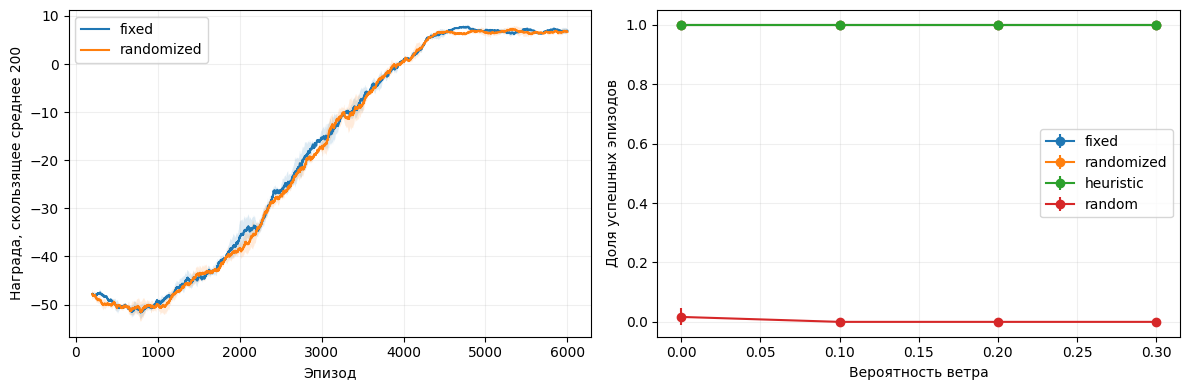

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for method in ['fixed', 'randomized']:
    curves = []
    for seed in [11, 22, 33]:
        values = training.query('method == @method and seed == @seed')['reward'].rolling(200).mean().to_numpy()
        curves.append(values)
    curves = np.asarray(curves)
    average, spread = curves.mean(axis=0), curves.std(axis=0)
    axes[0].plot(np.arange(1, 6001), average, label=method)
    axes[0].fill_between(np.arange(1, 6001), average - spread, average + spread, alpha=0.15)
for method in ['fixed', 'randomized', 'heuristic', 'random']:
    values = summary.loc[method]
    axes[1].errorbar(values.index, values['success']['mean'], yerr=values['success']['std'].fillna(0), marker='o', label=method)
axes[0].set(xlabel='Эпизод', ylabel='Награда, скользящее среднее 200')
axes[1].set(xlabel='Вероятность ветра', ylabel='Доля успешных эпизодов', ylim=(-0.05, 1.05))
for axis in axes:
    axis.legend()
    axis.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(ARTIFACTS / 'learning_and_robustness.png', dpi=150)
plt.show()

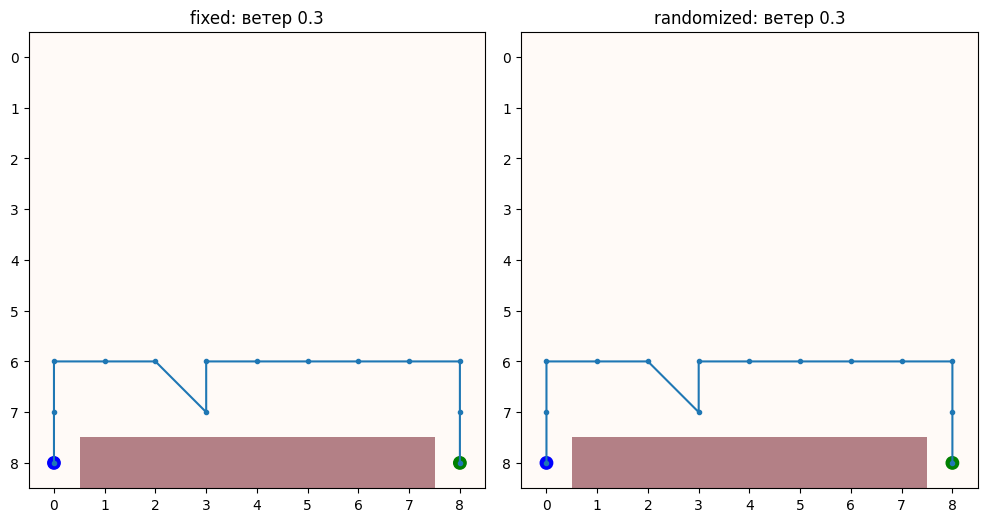

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for axis, method in zip(axes, ['fixed', 'randomized']):
    env = WindCliff(wind=0.3)
    state, _ = env.reset(seed=9001100)
    positions = [env.position.copy()]
    done = False
    while not done:
        state, _, terminated, truncated, _ = env.step(int(policies[method, 11][state].argmax()))
        positions.append(env.position.copy())
        done = terminated or truncated
    positions = np.array(positions)
    grid = np.zeros((9, 9))
    grid[8, 1:8] = 1
    axis.imshow(grid, cmap='Reds', vmin=0, vmax=1, alpha=0.5)
    axis.plot(positions[:, 1], positions[:, 0], '-o', markersize=3)
    axis.scatter([0, 8], [8, 8], c=['blue', 'green'], s=80)
    axis.set(title=f'{method}: ветер 0.3', xticks=range(9), yticks=range(9))
fig.tight_layout()
fig.savefig(ARTIFACTS / 'trajectories.png', dpi=150)
plt.show()

## Ограничения
Это небольшой эксперимент с тремя обучениями каждого варианта. Полосы на графиках показывают разброс по seed, а не доверительные интервалы. Проверены несколько конкретных уровней ветра; из них нельзя делать вывод о произвольном изменении динамики. Рандомизация создаёт частичную наблюдаемость, а табличная политика не использует историю. Сравниваются и эффективность, и безопасность: длинный маршрут может быть успешным, но давать меньшую награду.

Для запуска нужны NumPy, pandas, matplotlib и Gymnasium. Ноутбук содержит среду, обучение и оценку; внешние данные не требуются.

In [7]:
versions = {'python': platform.python_version()}
for package in ['numpy', 'pandas', 'matplotlib', 'gymnasium']:
    versions[package] = importlib.metadata.version(package)
print(versions)
(ARTIFACTS / 'versions.json').write_text(json.dumps(versions, indent=2))

{'python': '3.11.15', 'numpy': '1.26.4', 'pandas': '2.3.3', 'matplotlib': '3.10.9', 'gymnasium': '1.4.0'}


117

## Ответ на исследовательский вопрос

Гипотеза о преимуществе рандомизации в этом эксперименте не подтвердилась. При всех четырёх уровнях ветра оба обученных варианта достигали цели в 60 из 60 эпизодов, падений не было. При p=0.3 средняя награда 6,37, средняя длина 14,63 шага, против 9,00 и 12 шагов без ветра. Результаты двух методов на тестовых траекториях совпали, хотя таблицы Q обучались отдельно.

Безопасная эвристика также достигает цели во всех эпизодах, но при p=0.3 требует в среднем 28,88 шага и даёт награду -7,88. Случайная политика при таком ветре падает в 100% эпизодов. То есть задача решается осмысленной политикой, но выбранного усложнения недостаточно, чтобы показать преимущество рандомизации.

Причина видна на траекториях: уже обучение с постоянным p=0.1 учит держать запас до обрыва и возвращаться вверх после сноса. Одинаково безопасный маршрут годится и при p=0.3. Это ограничение среды, а не доказательство бесполезности domain randomization. Для продолжения можно добавить редкие порывы на несколько клеток и заранее зафиксировать новый эксперимент. В текущую проверку это изменение не вносилось.